## Latihan Mandiri (Tugas 1)
Nama   : Raudhatul Jannahㅤㅤ
NIM    : 2411512016ㅤㅤ
Matkul : Pemrograman paralel

# 1. Klasifikasi Flynn

a. Operasi `arr + arr` pada NumPy array 

Operasi `arr + arr` dapat dikategorikan sebagai SIMD (Single Instruction, Multiple Data). NumPy melakukan operasi ini secara vectorized. Satu instruksi penjumlahan diterapkan sekaligus ke seluruh elemen array menggunakan instruksi SIMD tingkat hardware misalnya AVX/SSE pada CPU, bukan diproses satu-per-satu lewat interpreter Python.

b. Program Python biasa (tanpa threading/multiprocessing) yang membaca file lalu memproses baris demi baris
Program ini termasuk kategori SISD (Single Instruction, Single Data). Sistem hanya menjalankan satu alur instruksi secara sekuensial pada satu inti prosesor, memproses satu data pada satu waktu.

c. Cluster komputer, tiap node menjalankan simulasi cuaca berbeda untuk wilayah berbeda secara independen
Termasuk kategori MIMD (Multiple Instruction, Multiple Data). Terdapat banyak prosesor/node yang beroperasi secara mandiri dengan instruksi dan data yang berbeda-beda untuk masing-masing wilayah. Kategori yang mencakup sebagian besar sistem distributed memory atau cluster HPC.

# 2. Analisis Hukum Amdahl (P = 0.85)

In [1]:
# Mengimpor NumPy untuk perhitungan numerik.
import numpy as np
# Mengimpor Matplotlib untuk membuat grafik.
import matplotlib.pyplot as plt

# Membuat fungsi untuk menghitung speedup menggunakan Hukum Amdahl.
def amdahl_speedup(P, N):
    return 1 / ((1 - P) + P / N)  # Menghitung dan mengembalikan nilai speedup.

# Menentukan 85% bagian program dapat diparalelkan.
P = 0.85
# Menentukan jumlah prosesor yang akan diuji.
Ns = [2, 4, 8, 16, 32, 64]

# Menampilkan judul kolom hasil perhitungan.
print(f"{'N':>4} | {'Speedup S(N)':>14} | {'Kenaikan dari N sebelumnya':>28}")
# Membuat garis pemisah tabel.
print("-" * 55)
# Menginisialisasi nilai speedup sebelumnya.
prev = None
# Menyiapkan list untuk menyimpan hasil speedup.
speedups = []
# Mengulangi perhitungan untuk setiap jumlah prosesor.
for N in Ns:
    # Menghitung speedup berdasarkan jumlah prosesor.
    s = amdahl_speedup(P, N)
    # Menyimpan hasil speedup ke dalam list.
    speedups.append(s)
    # Menghitung kenaikan speedup dari hasil sebelumnya.
    delta = f"{s - prev:.4f}" if prev is not None else "-"
    # Menampilkan jumlah prosesor, speedup, dan kenaikannya.
    print(f"{N:>4} | {s:>14.4f} | {delta:>28}")
    # Menyimpan speedup saat ini sebagai nilai sebelumnya.
    prev = s

# Menghitung batas maksimum speedup secara teoritis.
s_max = 1 / (1 - P)
# Menampilkan batas maksimum speedup saat jumlah prosesor tak terhingga.
print(f"\nBatas speedup maksimum teoritis saat N -> tak hingga: 1/(1-P) = {s_max:.4f}x")


   N |   Speedup S(N) |   Kenaikan dari N sebelumnya
-------------------------------------------------------
   2 |         1.7391 |                            -
   4 |         2.7586 |                       1.0195
   8 |         3.9024 |                       1.1438
  16 |         4.9231 |                       1.0206
  32 |         5.6637 |                       0.7406
  64 |         6.1244 |                       0.4607

Batas speedup maksimum teoritis saat N -> tak hingga: 1/(1-P) = 6.6667x


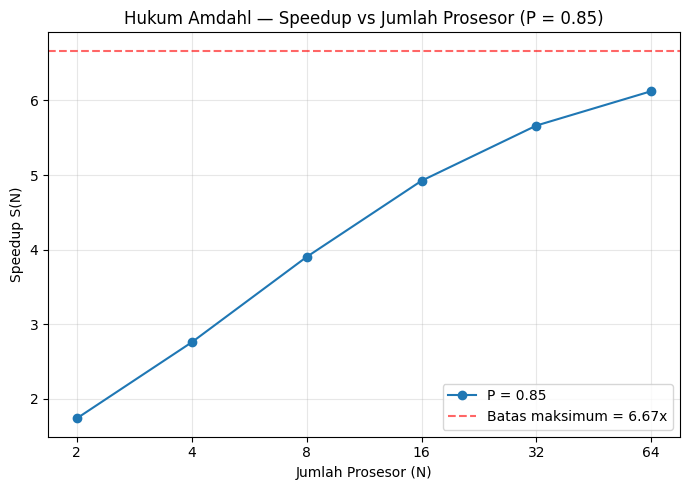

In [2]:
# Membuat ukuran gambar grafik 7x5 inci.
plt.figure(figsize=(7, 5))

# Membuat grafik hubungan jumlah prosesor dengan nilai speedup.
plt.plot(Ns, speedups, marker='o', color='tab:blue', label=f"P = {P}")

# Menambahkan garis batas maksimum speedup secara teoritis.
plt.axhline(s_max, color='red', linestyle='--', alpha=0.6, label=f"Batas maksimum = {s_max:.2f}x")

# Memberikan judul pada grafik.
plt.title("Hukum Amdahl — Speedup vs Jumlah Prosesor (P = 0.85)")

# Memberikan nama pada sumbu X.
plt.xlabel("Jumlah Prosesor (N)")

# Memberikan nama pada sumbu Y.
plt.ylabel("Speedup S(N)")

# Mengubah skala sumbu X menjadi logaritmik berbasis 2.
plt.xscale('log', base=2)

# Menampilkan semua nilai N pada sumbu X.
plt.xticks(Ns, Ns)

# Menambahkan garis grid agar grafik lebih mudah dibaca.
plt.grid(alpha=0.3)

# Menampilkan keterangan grafik.
plt.legend()

# Menyesuaikan tata letak agar elemen grafik tidak bertumpuk.
plt.tight_layout()

# Menampilkan grafik.
plt.show()

Dari tabel kenaikan speedup di atas, terlihat pola:
| Perubahan N | Kenaikan speedup |
|---|---|
| 2 → 4 | ≈ +1.02 |
| 4 → 8 | ≈ +1.14 |
| 8 → 16 | ≈ +1.02 |
| 16 → 32 | ≈ +0.74 |
| 32 → 64 | ≈ +0.46 |

Kenaikan speedup mulai jelas mengecil (kurang dari ±0.5, atau kurang dari ~10% dari speedup saat itu)  mulai sekitar N = 32 menuju N = 64. Bahkan pada N = 64, speedup baru mencapai ≈ 6.06x masih jauh dari batas maksimum teoritis 1/(1-P) = 6.67x. Namun setiap penggandaan prosesor sesudahnya hanya menambah pecahan kecil dari speedup. Ini merupakan konsekuensi langsung dari Hukum Amdahl, karena 15% bagian program bersifat serial dan tidak bisa dipercepat berapa pun banyaknya prosesor, komponen `P/N` (bagian paralel) menyusut menuju nol seiring N membesar, sehingga total waktu didominasi oleh porsi serial `(1-P)`. Grafik menunjukkan kurva mulai melandai (saturasi) persis di rentang N=16–64, yaitu titik di mana investasi menambah prosesor tidak lagi sebanding dengan manfaat speedup yang didapat.

# 3. Benchmark Mandiri


In [3]:
# Mengimpor library time untuk mengukur waktu eksekusi.
import time

# Mengimpor timeit untuk melakukan pengukuran waktu berulang.
import timeit

# Mendefinisikan fungsi untuk mencari bilangan prima hingga n.
def hitung_prima(n):

    # Menyediakan list untuk menyimpan bilangan prima.
    primes = []

    # Memeriksa setiap bilangan dari 2 hingga n-1.
    for num in range(2, n):

        # Menganggap bilangan saat ini adalah bilangan prima.
        is_prime = True

        # Mengecek pembagi hingga akar kuadrat dari bilangan.
        for i in range(2, int(num ** 0.5) + 1):

            # Mengecek apakah bilangan habis dibagi i.
            if num % i == 0:

                # Menandai bilangan sebagai bukan prima.
                is_prime = False

                # Menghentikan pengecekan jika ditemukan pembagi.
                break

        # Menambahkan bilangan ke list jika merupakan bilangan prima.
        if is_prime:
            primes.append(num)

    # Mengembalikan list bilangan prima yang ditemukan.
    return primes


# Menentukan ukuran input yang akan digunakan dalam pengujian.
input_sizes = [10_000, 30_000, 60_000, 100_000]

# Menyediakan list untuk menyimpan seluruh hasil pengukuran.
results = []

# Melakukan pengujian untuk setiap ukuran input.
for n in input_sizes:

    # Mengukur waktu eksekusi satu kali menggunakan perf_counter.
    start = time.perf_counter()

    # Menjalankan fungsi pencarian bilangan prima.
    hasil = hitung_prima(n)

    # Menghitung waktu yang diperlukan untuk eksekusi.
    waktu_pc = time.perf_counter() - start

    # Mengukur waktu eksekusi sebanyak 3 kali menggunakan timeit.
    waktu_timeit_list = timeit.repeat(
        stmt="hitung_prima(n)",
        globals={"hitung_prima": hitung_prima, "n": n},
        number=1,
        repeat=3,
    )

    # Menghitung rata-rata waktu dari 3 kali pengukuran.
    waktu_timeit_avg = sum(waktu_timeit_list) / len(waktu_timeit_list)

    # Mengambil waktu tercepat dari 3 kali pengukuran.
    waktu_timeit_best = min(waktu_timeit_list)

    # Menyimpan semua hasil pengukuran ke dalam list results.
    results.append({
        "N": n,
        "jumlah_prima": len(hasil),
        "perf_counter (detik)": waktu_pc,
        "timeit rata-rata (detik)": waktu_timeit_avg,
        "timeit terbaik (detik)": waktu_timeit_best,
    })


# Menampilkan judul kolom tabel hasil.
print(f"{'N':>10} | {'#Prima':>8} | {'perf_counter':>14} | {'timeit rata-rata':>18} | {'timeit terbaik':>16}")

# Membuat garis pemisah tabel.
print("-" * 78)

# Menampilkan setiap hasil pengukuran dalam bentuk tabel.
for r in results:
    print(f"{r['N']:>10} | {r['jumlah_prima']:>8} | {r['perf_counter (detik)']:>14.4f} | "
          f"{r['timeit rata-rata (detik)']:>18.4f} | {r['timeit terbaik (detik)']:>16.4f}")

         N |   #Prima |   perf_counter |   timeit rata-rata |   timeit terbaik
------------------------------------------------------------------------------
     10000 |     1229 |         0.0108 |             0.0087 |           0.0067
     30000 |     3245 |         0.0468 |             0.0595 |           0.0279
     60000 |     6057 |         0.0685 |             0.0670 |           0.0662
    100000 |     9592 |         0.1394 |             0.1728 |           0.1347


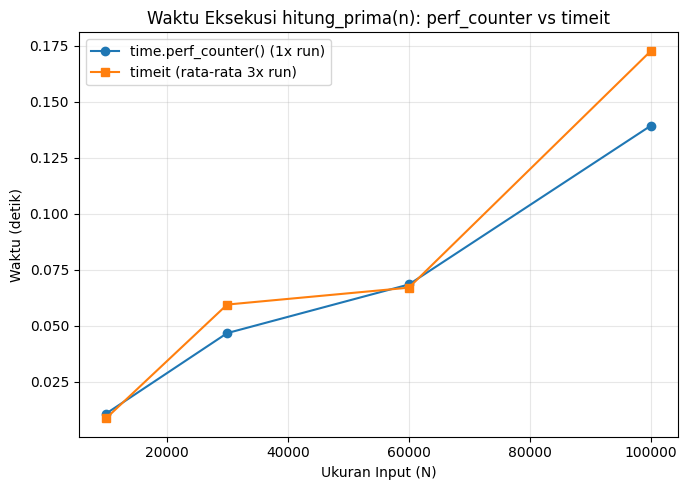

In [ ]:
# Plot perbandingan waktu eksekusi: perf_counter vs timeit (rata-rata)
# Mengambil nilai ukuran input (N) dari hasil pengujian.
Ns_bench = [r["N"] for r in results]

# Mengambil waktu eksekusi menggunakan perf_counter.
t_pc = [r["perf_counter (detik)"] for r in results]

# Mengambil rata-rata waktu eksekusi menggunakan timeit.
t_timeit = [r["timeit rata-rata (detik)"] for r in results]

# Membuat area grafik dengan ukuran 7x5 inci.
plt.figure(figsize=(7, 5))

# Membuat garis grafik untuk hasil perf_counter.
plt.plot(Ns_bench, t_pc, marker='o', label="time.perf_counter() (1x run)")

# Membuat garis grafik untuk hasil rata-rata timeit.
plt.plot(Ns_bench, t_timeit, marker='s', label="timeit (rata-rata 3x run)")

# Memberikan judul pada grafik.
plt.title("Waktu Eksekusi hitung_prima(n): perf_counter vs timeit")

# Memberikan nama pada sumbu X.
plt.xlabel("Ukuran Input (N)")

# Memberikan nama pada sumbu Y.
plt.ylabel("Waktu (detik)")

# Menambahkan grid agar grafik lebih mudah dibaca.
plt.grid(alpha=0.3)

# Menampilkan keterangan untuk setiap garis pada grafik.
plt.legend()

# Menyesuaikan tata letak grafik agar lebih rapi.
plt.tight_layout()

# Menampilkan grafik.
plt.show()


Perbandingan hasil kedua metode:
Kedua metode menunjukkan pola yang serupa, yaitu waktu eksekusi `hitung_prima(n)` meningkat secara non-linear terhadap N, sejalan dengan kompleksitas algoritma yang mendekati O(n·√n). Hasil pengukuran menggunakan `time.perf_counter()` sekali cenderung lebih fluktuatif atau terkadang lebih tinggi dibandingkan `timeit` karena hanya menggunakan satu sampel sehingga lebih mudah dipengaruhi noise, seperti aktivitas proses lain, kondisi cache, atau garbage collector. Sebaliknya, `timeit` menghasilkan pengukuran yang lebih stabil karena melakukan beberapa kali pengulangan dan menggunakan hasil rata-rata atau nilai minimum untuk mengurangi pengaruh gangguan sistem. Oleh karena itu, `timeit` lebih direkomendasikan untuk benchmarking yang membutuhkan hasil lebih akurat dan konsisten, sedangkan `perf_counter()` tetap cocok digunakan untuk pengukuran waktu secara cepat dalam satu kali eksekusi program.

# 4. Refleksi Singkat
Hukum Amdahl lebih sesuai digunakan pada kondisi ketika ukuran masalah tetap dan penambahan prosesor bertujuan mempercepat penyelesaian pekerjaan yang sama, yang dikenal sebagai strong scaling. Contohnya adalah proses rendering sebuah video dengan durasi tetap. Penambahan jumlah core dapat mempercepat proses, tetapi peningkatannya terbatas karena masih terdapat bagian serial, seperti tahap penggabungan akhir, yang tidak dapat dijalankan secara paralel. Sementara itu, Hukum Gustafson lebih relevan ketika ukuran masalah dapat diperbesar seiring bertambahnya sumber daya komputasi, atau disebut weak scaling. Pendekatan ini banyak digunakan dalam HPC dan simulasi ilmiah, misalnya prakiraan cuaca. Dengan menambah node, cakupan atau resolusi simulasi dapat diperbesar tanpa memperpanjang waktu pengerjaan secara signifikan. Jadi, Amdahl berfokus pada menyelesaikan pekerjaan yang sama dengan lebih cepat, sedangkan Gustafson berfokus pada menyelesaikan pekerjaan yang lebih besar dalam waktu yang relatif sama.